# Northwind: Exploratory Data Analysis

Purpose: get to know the dataset before choosing the business questions for HW 3.
This notebook is exploratory. The final, reproducible analysis lives in `src/`.

**Revenue definition used here:** `UnitPrice × Quantity × (1 − Discount)` from the order lines (the price actually charged, net of discount).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from load_data import load_tables

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)
usd = mtick.FuncFormatter(lambda x, _: f"${x/1000:,.0f}k")

t = load_tables()

## 1. What's in the file

In [2]:
overview = pd.DataFrame({
    name: {"rows": len(df), "columns": df.shape[1],
           "cells missing": int(df.isna().sum().sum())}
    for name, df in t.items()
}).T
overview

,rows,columns,cells missing
categories,8,3,0
customers,91,11,83
employees,9,17,5
order_details,2155,7,0
orders,830,14,547
shippers,3,3,0
products,77,10,0
suppliers,29,12,62


In [3]:
# Columns with missing values (where they exist)
missing = {name: df.isna().sum()[lambda s: s > 0] for name, df in t.items()}
pd.concat({k: v for k, v in missing.items() if len(v)}, names=["table", "column"]).to_frame("missing")

missing
table     column                 
customers Region               60
          PostalCode            1
          Fax                  22
employees Region                4
          ReportsTo             1
orders    ShippedDate          21
          ShipRegion          507
          ShipPostalCode       19
suppliers Region               20
          Fax                  16
          HomePage             26

How the tables connect:

`Orders Details` (one row per product on an order) → `Orders` (by OrderID) → `Customers`, `Employees`, `Shippers` (ShipVia).
`Orders Details` → `Product` (by ProductID) → `Categories`, `Suppliers`.

## 2. Build one order-line table

In [4]:
lines = (
    t["order_details"]
    .merge(t["orders"], on="OrderID", how="left", validate="many_to_one")
    .merge(t["customers"][["CustomerID", "CompanyName", "Country"]]
           .rename(columns={"CompanyName": "Customer", "Country": "CustomerCountry"}),
           on="CustomerID", how="left", validate="many_to_one")
    .merge(t["products"][["ProductID", "ProductName", "CategoryID", "SupplierID", "Price", "Discontinued"]],
           on="ProductID", how="left", validate="many_to_one")
    .merge(t["categories"][["CategoryID", "CategoryName"]], on="CategoryID", how="left")
    .merge(t["employees"][["EmployeeID", "FirstName", "LastName", "Title"]], on="EmployeeID", how="left")
    .merge(t["shippers"].rename(columns={"ShipperID": "ShipVia", "CompanyName": "Shipper"})[["ShipVia", "Shipper"]],
           on="ShipVia", how="left")
)
lines["Revenue"] = lines["UnitPrice"] * lines["Quantity"] * (1 - lines["Discount"])
lines["Month"] = lines["OrderDate"].dt.to_period("M")
lines["Year"] = lines["OrderDate"].dt.year
lines["Employee"] = lines["FirstName"] + " " + lines["LastName"]

# Sanity checks: the joins must not add or lose rows, and every key must match
assert len(lines) == len(t["order_details"])
print("Order lines:", len(lines))
print("Unmatched keys:", lines[["OrderDate", "Customer", "ProductName", "CategoryName", "Employee", "Shipper"]].isna().sum().to_dict())
print(f"Total revenue: ${lines['Revenue'].sum():,.0f}")
print("Order date range:", lines["OrderDate"].min().date(), "to", lines["OrderDate"].max().date())

Order lines: 2155
Unmatched keys: {'OrderDate': 0, 'Customer': 0, 'ProductName': 0, 'CategoryName': 0, 'Employee': 0, 'Shipper': 0}
Total revenue: $1,265,793
Order date range: 1996-07-04 to 1998-05-06


In [5]:
orders = lines.groupby("OrderID").agg(
    OrderDate=("OrderDate", "first"), RequiredDate=("RequiredDate", "first"),
    ShippedDate=("ShippedDate", "first"), Customer=("Customer", "first"),
    Country=("CustomerCountry", "first"), Employee=("Employee", "first"),
    Shipper=("Shipper", "first"), Freight=("Freight", "first"),
    Revenue=("Revenue", "sum"), Lines=("ProductID", "count"),
)
orders.describe()[["Revenue", "Freight", "Lines"]]

,Revenue,Freight,Lines
count,830.00,830.00,830.00
mean,"1,525.05",78.24,2.60
min,12.50,0.02,1.00
25%,456.69,13.38,2.00
50%,943.25,41.36,2.00
75%,"1,882.20",91.43,3.00
max,"16,387.50","1,007.64",25.00
std,"1,845.18",116.78,1.33


## 3. Sales over time

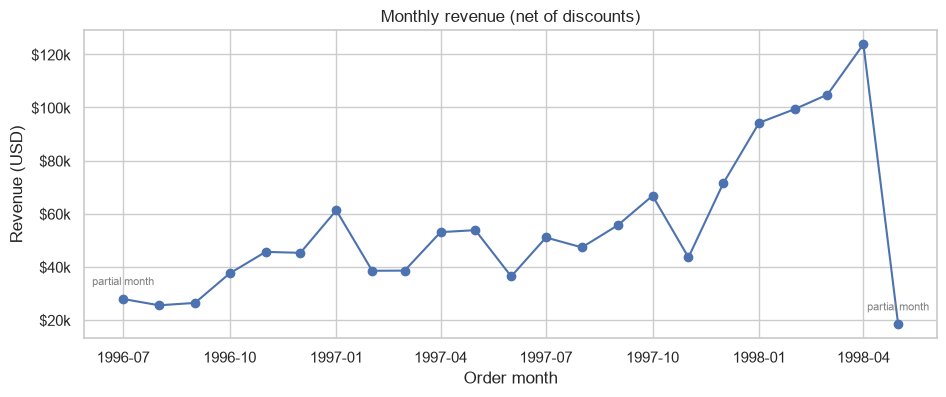

,Revenue,Orders,DaysCovered
Month,,,
1997-12,"71,398.43",48,31
1998-01,"94,222.11",55,30
1998-02,"99,415.29",54,26
1998-03,"104,854.15",73,30
1998-04,"123,798.68",74,30
1998-05,"18,333.63",14,6


In [6]:
monthly = lines.groupby("Month").agg(Revenue=("Revenue", "sum"), Orders=("OrderID", "nunique"))
days_in_data = lines.groupby("Month")["OrderDate"].agg(lambda s: s.dt.day.max() - s.dt.day.min() + 1)
monthly["DaysCovered"] = days_in_data

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index.to_timestamp(), monthly["Revenue"], marker="o")
ax.yaxis.set_major_formatter(usd)
ax.set(title="Monthly revenue (net of discounts)", xlabel="Order month", ylabel="Revenue (USD)")
for m in [monthly.index[0], monthly.index[-1]]:
    ax.annotate("partial month", (m.to_timestamp(), monthly.loc[m, "Revenue"]),
                textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8, color="gray")
plt.show()
monthly.tail(6)

In [7]:
# Compare like-for-like: Jan–Apr in 1997 vs 1998
lines["MonthNum"] = lines["OrderDate"].dt.month
jan_apr = lines[lines["MonthNum"] <= 4].groupby("Year").agg(
    Revenue=("Revenue", "sum"), Orders=("OrderID", "nunique"))
jan_apr["Revenue growth"] = jan_apr["Revenue"].pct_change()
jan_apr.loc[[1997, 1998]]

,Revenue,Orders,Revenue growth
Year,,,
1997,"191,321.88",123,NaN
1998,"422,290.24",256,1.21


## 4. Customers and markets

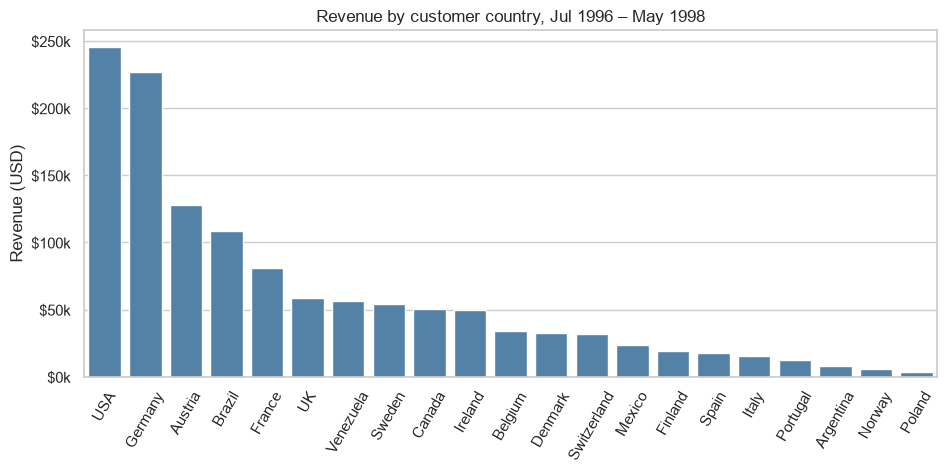

,Revenue,Customers,Orders,Share
CustomerCountry,,,,
USA,"245,678.26",13,122,0.19
Germany,"226,916.58",11,120,0.18
Austria,"128,003.84",2,40,0.10
Brazil,"108,789.18",9,84,0.09
France,"80,918.32",10,76,0.06
UK,"58,971.31",7,56,0.05
Venezuela,"56,810.63",4,46,0.04
Sweden,"54,495.14",2,37,0.04
Canada,"50,196.29",3,30,0.04


In [8]:
by_country = lines.groupby("CustomerCountry").agg(
    Revenue=("Revenue", "sum"), Customers=("CustomerID", "nunique"), Orders=("OrderID", "nunique")
).sort_values("Revenue", ascending=False)
by_country["Share"] = by_country["Revenue"] / by_country["Revenue"].sum()

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(x=by_country.index, y=by_country["Revenue"], color="steelblue", ax=ax)
ax.yaxis.set_major_formatter(usd)
ax.set(title="Revenue by customer country, Jul 1996 – May 1998", xlabel="", ylabel="Revenue (USD)")
ax.tick_params(axis="x", rotation=60)
plt.show()
by_country.head(10)

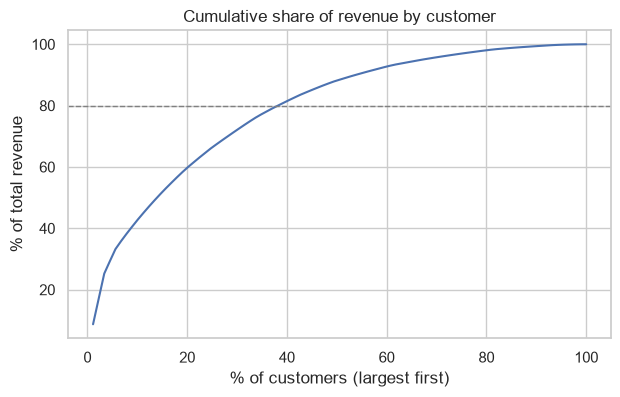

89 customers placed orders (91 in the customer list).
Top 10 customers = 45% of revenue; 34 customers (38%) make up 80%.


,Revenue
Customer,
QUICK-Stop,"110,277.31"
Ernst Handel,"104,874.98"
Save-a-lot Markets,"104,361.95"
Rattlesnake Canyon Grocery,"51,097.80"
Hungry Owl All-Night Grocers,"49,979.90"
Hanari Carnes,"32,841.37"
Königlich Essen,"30,908.38"
Folk och fä HB,"29,567.56"
Mère Paillarde,"28,872.19"


In [9]:
# How concentrated is revenue among customers? (Pareto curve)
cust = lines.groupby("Customer")["Revenue"].sum().sort_values(ascending=False)
cum = cust.cumsum() / cust.sum()
pct_customers = (pd.Series(range(1, len(cust) + 1)) / len(cust)).values

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pct_customers * 100, cum.values * 100)
ax.axhline(80, ls="--", c="gray", lw=1)
ax.set(title="Cumulative share of revenue by customer", xlabel="% of customers (largest first)",
       ylabel="% of total revenue")
plt.show()

n80 = int((cum < 0.8).sum() + 1)
print(f"{len(cust)} customers placed orders ({len(t['customers'])} in the customer list).")
print(f"Top 10 customers = {cum.iloc[9]:.0%} of revenue; {n80} customers ({n80/len(cust):.0%}) make up 80%.")
cust.head(10).to_frame("Revenue")

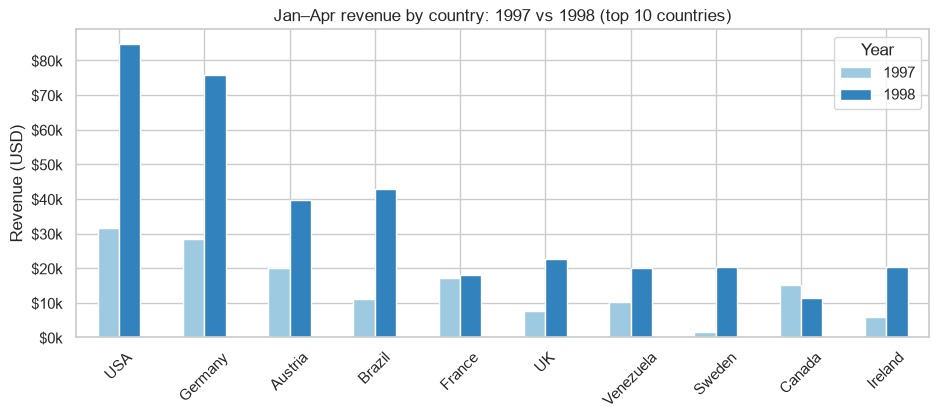

In [10]:
# Which markets grew? Jan–Apr 1997 vs Jan–Apr 1998, top 10 countries
ytd = (lines[lines["MonthNum"] <= 4]
       .pivot_table(index="CustomerCountry", columns="Year", values="Revenue", aggfunc="sum", fill_value=0))
ytd = ytd.loc[by_country.index[:10], [1997, 1998]]
ax = ytd.plot.bar(figsize=(11, 4), color=["#9ecae1", "#3182bd"])
ax.yaxis.set_major_formatter(usd)
ax.set(title="Jan–Apr revenue by country: 1997 vs 1998 (top 10 countries)", xlabel="", ylabel="Revenue (USD)")
ax.legend(title="Year")
plt.xticks(rotation=45)
plt.show()

## 5. Products and categories

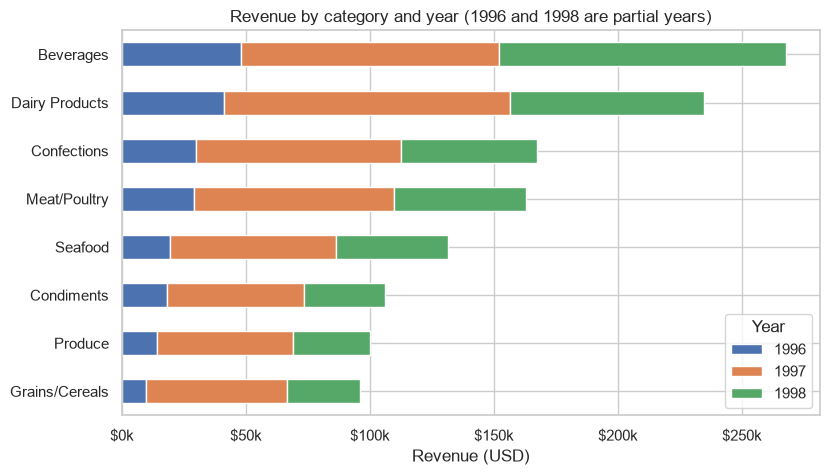

Year,1996,1997,1998,Total
CategoryName,,,,
Beverages,"47,919.00","103,924.31","116,024.88","267,868.18"
Dairy Products,"40,980.45","115,387.64","78,139.20","234,507.29"
Confections,"29,685.55","82,657.75","55,013.92","167,357.23"
Meat/Poultry,"28,813.66","80,975.11","53,233.59","163,022.36"
Seafood,"19,391.22","66,959.22","44,911.29","131,261.74"
Condiments,"17,900.38","55,368.59","32,778.11","106,047.09"
Produce,"13,885.78","54,940.77","31,158.03","99,984.58"
Grains/Cereals,"9,507.92","56,871.82","29,364.84","95,744.59"


In [11]:
cat_year = lines.pivot_table(index="CategoryName", columns="Year", values="Revenue", aggfunc="sum")
cat_year["Total"] = cat_year.sum(axis=1)
cat_year = cat_year.sort_values("Total", ascending=False)

ax = cat_year.drop(columns="Total").plot.barh(figsize=(9, 5), stacked=True)
ax.xaxis.set_major_formatter(usd)
ax.set(title="Revenue by category and year (1996 and 1998 are partial years)", xlabel="Revenue (USD)", ylabel="")
ax.invert_yaxis()
plt.show()
cat_year

In [12]:
prod = lines.groupby(["ProductName", "CategoryName", "Discontinued"]).agg(
    Revenue=("Revenue", "sum"), Units=("Quantity", "sum"), AvgPrice=("UnitPrice", "mean")
).reset_index().sort_values("Revenue", ascending=False)
prod["Share"] = prod["Revenue"] / prod["Revenue"].sum()
print(f"Top 5 products = {prod['Share'].head(5).sum():.0%} of revenue, out of {len(prod)} products sold.")
prod.head(10)

Top 5 products = 31% of revenue, out of 77 products sold.


,ProductName,CategoryName,Discontinued,Revenue,Units,AvgPrice,Share
11,Côte de Blaye,Beverages,False,"141,396.73",623,245.93,0.11
68,Thüringer Rostbratwurst,Meat/Poultry,True,"80,368.67",746,116.04,0.06
51,Raclette Courdavault,Dairy Products,False,"71,155.70",1496,51.13,0.06
66,Tarte au sucre,Confections,False,"47,234.97",1083,46.41,0.04
3,Camembert Pierrot,Dairy Products,False,"46,825.48",1577,32.13,0.04
17,Gnocchi di nonna Alice,Grains/Cereals,False,"42,593.06",1263,35.42,0.03
36,Manjimup Dried Apples,Produce,False,"41,819.65",886,50.55,0.03
0,Alice Mutton,Meat/Poultry,True,"32,698.38",978,36.47,0.03
4,Carnarvon Tigers,Seafood,False,"29,171.88",539,59.72,0.02
55,Rössle Sauerkraut,Produce,True,"25,696.64",640,41.98,0.02


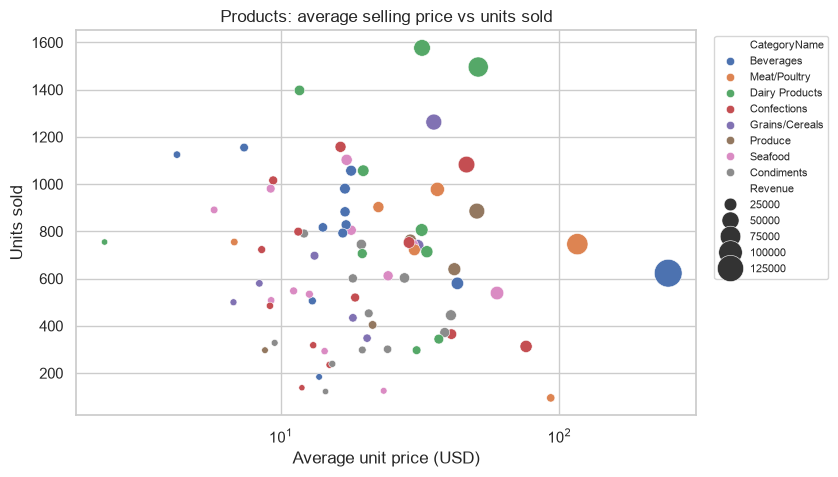

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=prod, x="AvgPrice", y="Units", size="Revenue", hue="CategoryName", sizes=(20, 400), ax=ax)
ax.set(title="Products: average selling price vs units sold", xlabel="Average unit price (USD)",
       ylabel="Units sold", xscale="log")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.show()

## 6. Discounts

Lines with unusual 1-6% discounts: 8 - all from order(s) [11077]
39% of order lines carry a discount.
Revenue given up through discounts: $88,666 (6.5% of gross).


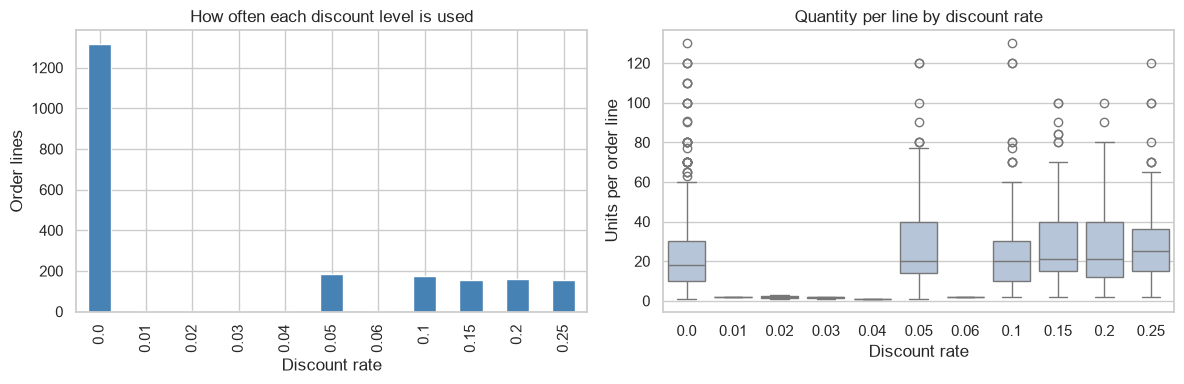

,count,mean,median
Discount,,,
0.00,1317,21.72,18.00
0.01,1,2.00,2.00
0.02,2,2.00,2.00
0.03,3,1.67,2.00
0.04,1,1.00,1.00
0.05,185,28.01,20.00
0.06,1,2.00,2.00
0.10,173,25.24,20.00
0.15,157,28.38,21.00


In [14]:
lines["Discount"] = lines["Discount"].round(2)  # stored values carry float noise, e.g. 0.15000001
odd = lines[lines["Discount"].isin([0.01, 0.02, 0.03, 0.04, 0.06])]
print("Lines with unusual 1-6% discounts:", len(odd), "- all from order(s)", odd["OrderID"].unique())
disc = lines.assign(Discounted=lines["Discount"] > 0)
print(f"{disc['Discounted'].mean():.0%} of order lines carry a discount.")
gross = (lines["UnitPrice"] * lines["Quantity"]).sum()
print(f"Revenue given up through discounts: ${gross - lines['Revenue'].sum():,.0f} "
      f"({1 - lines['Revenue'].sum()/gross:.1%} of gross).")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
lines["Discount"].value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="How often each discount level is used", xlabel="Discount rate", ylabel="Order lines")
sns.boxplot(data=lines, x="Discount", y="Quantity", ax=axes[1], color="lightsteelblue")
axes[1].set(title="Quantity per line by discount rate", xlabel="Discount rate", ylabel="Units per order line")
plt.tight_layout()
plt.show()
lines.groupby("Discount")["Quantity"].agg(["count", "mean", "median"])

## 7. Sales team

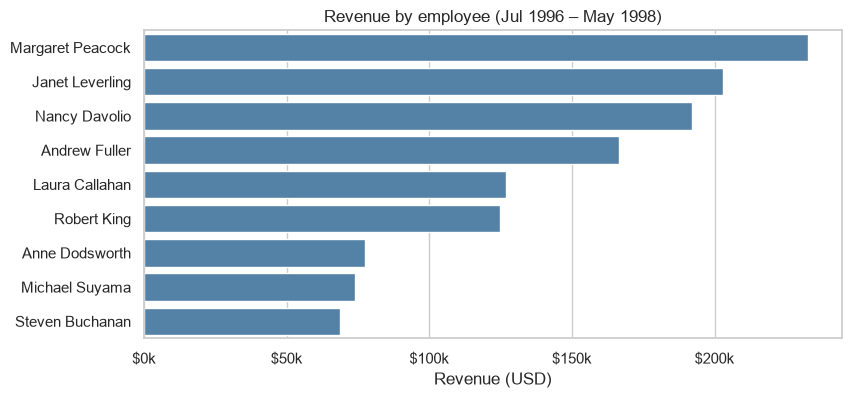

,Revenue,Orders,AvgOrder,Title,Country,HireDate
Employee,,,,,,
Margaret Peacock,"232,890.85",156,"1,492.89",Sales Representative,USA,1993-05-03
Janet Leverling,"202,812.84",127,"1,596.95",Sales Representative,USA,1992-04-01
Nancy Davolio,"192,107.60",123,"1,561.85",Sales Representative,USA,1992-05-01
Andrew Fuller,"166,537.76",96,"1,734.77","Vice President, Sales",USA,1992-08-14
Laura Callahan,"126,862.28",104,"1,219.83",Inside Sales Coordinator,USA,1994-03-05
Robert King,"124,568.24",72,"1,730.11",Sales Representative,UK,1994-01-02
Anne Dodsworth,"77,308.07",43,"1,797.86",Sales Representative,UK,1994-11-15
Michael Suyama,"73,913.13",67,"1,103.18",Sales Representative,UK,1993-10-17
Steven Buchanan,"68,792.28",42,"1,637.91",Sales Manager,UK,1993-10-17


In [15]:
emp = orders.groupby("Employee").agg(Revenue=("Revenue", "sum"), Orders=("Revenue", "size"),
                                     AvgOrder=("Revenue", "mean")).sort_values("Revenue", ascending=False)
emp = emp.join(t["employees"].assign(Employee=lambda d: d.FirstName + " " + d.LastName)
               .set_index("Employee")[["Title", "Country", "HireDate"]])

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=emp["Revenue"], y=emp.index, color="steelblue", ax=ax)
ax.xaxis.set_major_formatter(usd)
ax.set(title="Revenue by employee (Jul 1996 – May 1998)", xlabel="Revenue (USD)", ylabel="")
plt.show()
emp

## 8. Shipping and fulfilment

Orders not yet shipped: 21
Shipped orders that went out after the required date: 4.6%
Median days from order to shipment: 7


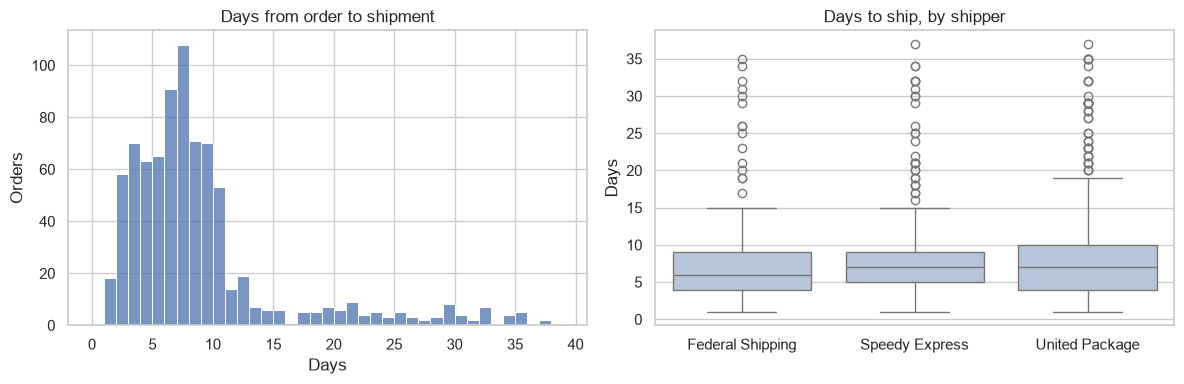

,Orders,LateRate,MedianDays,AvgFreight
Shipper,,,,
Federal Shipping,249,0.04,6.00,81.78
Speedy Express,245,0.05,7.00,65.45
United Package,315,0.05,7.00,87.48


In [16]:
o = orders.copy()
o["DaysToShip"] = (o["ShippedDate"] - o["OrderDate"]).dt.days
o["Late"] = o["ShippedDate"] > o["RequiredDate"]
shipped = o.dropna(subset=["ShippedDate"])

print(f"Orders not yet shipped: {o['ShippedDate'].isna().sum()}")
print(f"Shipped orders that went out after the required date: {shipped['Late'].mean():.1%}")
print(f"Median days from order to shipment: {shipped['DaysToShip'].median():.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(shipped["DaysToShip"], bins=range(0, 40), ax=axes[0])
axes[0].set(title="Days from order to shipment", xlabel="Days", ylabel="Orders")
sns.boxplot(data=shipped, x="Shipper", y="DaysToShip", ax=axes[1], color="lightsteelblue")
axes[1].set(title="Days to ship, by shipper", xlabel="", ylabel="Days")
plt.tight_layout()
plt.show()

shipped.groupby("Shipper").agg(Orders=("Late", "size"), LateRate=("Late", "mean"),
                               MedianDays=("DaysToShip", "median"), AvgFreight=("Freight", "mean"))

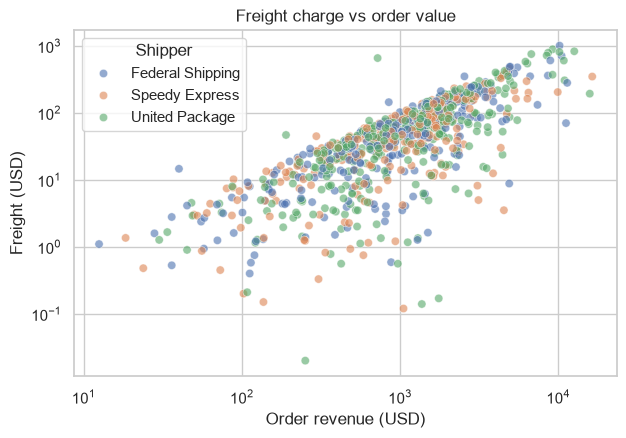

Rank (Spearman) correlation of freight with order value: 0.78
Freight as % of revenue overall: 5.1%


In [17]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=o, x="Revenue", y="Freight", hue="Shipper", alpha=0.6, ax=ax)
ax.set(title="Freight charge vs order value", xlabel="Order revenue (USD)", ylabel="Freight (USD)",
       xscale="log", yscale="log")
plt.show()
print("Rank (Spearman) correlation of freight with order value:",
      round(o["Revenue"].corr(o["Freight"], method="spearman"), 2))
print(f"Freight as % of revenue overall: {o['Freight'].sum() / o['Revenue'].sum():.1%}")

## 9. Inventory

In [18]:
p = t["products"].merge(t["categories"][["CategoryID", "CategoryName"]], on="CategoryID")
p["BelowReorder"] = (p["UnitsInStock"] <= p["ReorderLevel"]) & (p["Discontinued"] == 0)
p["StockValue"] = p["UnitsInStock"] * p["Price"]
print(f"Products: {len(p)}, discontinued: {int(p['Discontinued'].sum())}, "
      f"active at or below reorder level: {int(p['BelowReorder'].sum())}")
print(f"Active products at or below reorder level with nothing on order: "
      f"{int((p['BelowReorder'] & (p['UnitsOnOrder'] == 0)).sum())}")
p[p["BelowReorder"]][["ProductName", "CategoryName", "UnitsInStock", "ReorderLevel", "UnitsOnOrder"]]

Products: 77, discontinued: 8, active at or below reorder level: 18
Active products at or below reorder level with nothing on order: 1


,ProductName,CategoryName,UnitsInStock,ReorderLevel,UnitsOnOrder
0,Chang,Beverages,17,25,40
2,Aniseed Syrup,Condiments,13,25,70
6,Louisiana Hot Spiced Okra,Condiments,4,20,100
12,Longlife Tofu,Produce,4,5,20
14,Queso Cabrales,Dairy Products,22,30,30
22,Outback Lager,Beverages,15,30,10
24,Scottish Longbreads,Confections,6,15,10
25,Sir Rodney's Scones,Confections,3,5,40
35,Wimmers gute Semmelknödel,Grains/Cereals,22,30,80
38,Nord-Ost Matjeshering,Seafood,10,15,0


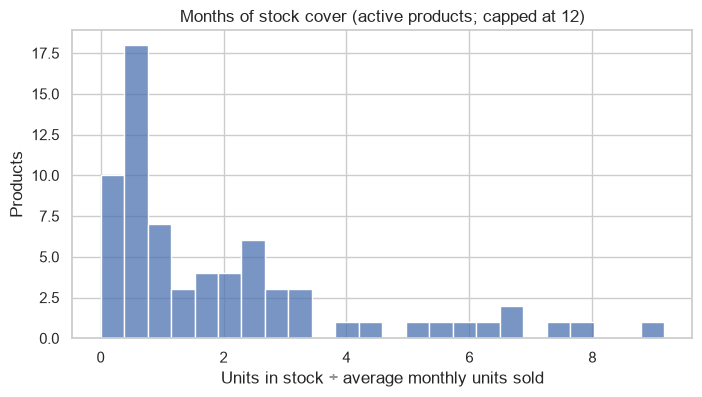

count   69.00
mean     2.03
std      2.14
min      0.00
25%      0.52
50%      1.08
75%      2.67
max      9.17
Name: MonthsOfCover, dtype: float64

In [19]:
# Stock on hand vs demand: months of cover per active product
months = lines["Month"].nunique()
demand = lines.groupby("ProductID")["Quantity"].sum() / months
p["MonthsOfCover"] = p["UnitsInStock"] / p["ProductID"].map(demand)
active = p[p["Discontinued"] == 0]

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(active["MonthsOfCover"].clip(upper=12), bins=24, ax=ax)
ax.set(title="Months of stock cover (active products; capped at 12)",
       xlabel="Units in stock ÷ average monthly units sold", ylabel="Products")
plt.show()
active["MonthsOfCover"].describe()

## 10. Main observations

**Scale.** $1.27M net revenue from 830 orders (2,155 order lines) placed by 89 customers, 4 Jul 1996 – 6 May 1998.
Both end months are partial (May 1998 has only 6 days), so compare like-for-like periods.

**Growth.** The business is growing fast. Jan–Apr 1998 revenue was $422k vs $191k in Jan–Apr 1997 (+121%), and orders doubled (256 vs 123).
Monthly revenue rose steadily to ~$124k in April 1998.

**Concentration (customers and markets).**
- USA ($246k) and Germany ($227k) together make up 37% of revenue.
- Austria is #3 ($128k) with only **2 customers**, and Ireland's $50k comes from a single customer.
- The top 3 customers (QUICK-Stop, Ernst Handel, Save-a-lot Markets) bring in ~$320k (25%). The top 10 bring in 45%.
- 2 customers in the customer list never ordered.

**Products.**
- Beverages is the largest category ($268k), but that is mostly one product: Côte de Blaye alone is $141k, **11% of all revenue**.
- 3 of the top 10 products by revenue are now **discontinued** (Thüringer Rostbratwurst at $80k, Alice Mutton, Rössle Sauerkraut). That revenue will need replacing.

**Discounts.**
- 39% of order lines are discounted, giving up $88.7k (6.5% of gross revenue).
- Discounted lines are somewhat larger (median 20–25 units vs 18 at full price). This is correlation only and could reflect who receives discounts, not that discounts cause bigger orders.
- The unusual 1–6% rates all come from one 25-line order (#11077), so they look like a one-off.

**Sales team.**
- Sales are spread unevenly across the 9 employees: Margaret Peacock $233k vs Steven Buchanan $69k.
- The 5 US-based staff outsell the 4 UK-based staff, but that may reflect territory and order count rather than skill.
- Average order size is fairly similar across employees ($1.1k–$1.8k).

**Fulfilment.**
- The median order ships in 7 days, 4.6% of shipped orders went out after the required date, and 21 orders are unshipped.
- The three shippers look similar on lateness (4–5%).
- Freight is about 5.1% of revenue and rises with order value (Spearman ρ ≈ 0.78).

**Inventory.**
- 18 of 69 active products are at or below their reorder level, and all but one (Nord-Ost Matjeshering) have stock on order.
- The median active product holds ~1 month of stock at its average sales rate.

**Data-quality notes.**
- Missing values are mostly harmless (Region, Fax, ShipRegion).
- `ShippedDate` is missing for 21 orders, meaning they are not yet shipped.
- Discount values carry float noise, so round them to 2 dp.

## 11. Candidate business questions (to choose from)

1. **Market focus:** Which countries and customers drive the 1998 growth, and where should sales attention go next?
2. **Customer concentration risk:** How dependent is Northwind on a few customers and single-customer markets, and what would losing one cost?
3. **Discount effectiveness:** Are discounts linked to larger or repeat orders, or are they mostly revenue given away?
4. **Product portfolio risk:** How exposed is revenue to one premium product and to discontinued products, and which products could replace them?
5. **Sales team performance:** Do the revenue differences between employees hold after accounting for territory, tenure, and customer mix?
6. **Fulfilment reliability and cost:** Which shippers, countries, or employees are linked to late shipments, and is freight priced sensibly relative to order value?
7. **Inventory risk:** Which fast-selling products are at risk of stocking out given current stock, reorder levels, and demand?